# TrafficSense — Exploratory Data Analysis (PEMS-BAY)

**Phase 2 · Dataset acquisition & validation → initial EDA**

Input: the validated, lossless Parquet in `data/processed/pems_bay/` (built from the immutable raw CSV in
`data/raw/pems_bay/`). All heavy lifting is done in **Spark**; only small aggregates are converted to pandas
for plotting. Figures are saved to `reports/figures/eda/`.

| § | Question |
|---|---|
| 1 | Is the processed data consistent with the validation report? |
| 2 | **Observation frequency** — how regularly does each sensor report, per month / day / sensor? |
| 3 | **Temporal distributions** — how does speed vary by hour, weekday/weekend, day-of-week, month? |
| 4 | Spatial view — where are the slow / unreliable sensors? |
| 5 | Provisional congestion levels — how imbalanced would Free / Moderate / Heavy classes be? |
| 6 | Key findings feeding Phase 5 (features) and Phase 6 (MLlib) |

> Timestamps are naive local Pacific wall-clock times, stored verbatim (Spark session time zone = UTC),
> so `hour` below is the **local** hour of day.

In [1]:
import sys, json
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql import functions as F, Window

from src.common.paths import processed_dataset_dir, VALIDATION_REPORT_DIR, FIGURES_DIR
from src.common.spark import get_spark

DATASET = "pems-bay"
PROC = processed_dataset_dir(DATASET)
FIG = FIGURES_DIR / "eda"
FIG.mkdir(parents=True, exist_ok=True)
SLOTS_PER_DAY = 288  # 24 h * 12 five-minute slots

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160, "display.max_columns", 30)

def save(fig, name):
    path = FIG / f"{name}.png"
    fig.savefig(path, dpi=130, bbox_inches="tight")
    print("saved", path.relative_to(ROOT))

spark = get_spark("trafficsense-eda")
print("Spark", spark.version, "| project", ROOT)

26/10/20 08:10:24 WARN Utils: Your hostname, ISCN5CG3384CH3 resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/10/20 08:10:24 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/20 08:10:25 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 3.5.9 | project /mnt/c/Users/ssis/Desktop/bdaa


## 1. Load processed data and reconcile with the validation report

In [2]:
readings = spark.read.parquet(str(PROC / "readings"))
sensors_meta = spark.read.parquet(str(PROC / "sensors")).toPandas()
validation = json.loads((VALIDATION_REPORT_DIR / "pems_bay_validation_report.json").read_text())
build_info = json.loads((PROC / "_build_info.json").read_text())

readings.printSchema()
print("validation status :", validation["overall_status"])
print("validated readings:", f"{validation['profile']['sensor_readings']:,}")
print("parquet readings  :", f"{build_info['readings']['rows']:,}")
assert build_info["readings"]["rows"] == validation["profile"]["sensor_readings"], "processed != validated"

root
 |-- ts: timestamp (nullable = true)
 |-- sensor_id: integer (nullable = true)
 |-- speed_mph: double (nullable = true)
 |-- is_missing: boolean (nullable = true)
 |-- date: date (nullable = true)
 |-- month: string (nullable = true)

validation status : PASS
validated readings: 16,937,700
parquet readings  : 16,937,700


In [3]:
r = (readings
     .withColumn("hour", F.hour("ts"))
     .withColumn("dow", F.dayofweek("ts"))              # 1 = Sunday ... 7 = Saturday
     .withColumn("is_weekend", F.col("dow").isin(1, 7))
     .cache())
valid = r.filter(~F.col("is_missing"))

overview = r.agg(
    F.count("*").alias("readings"),
    F.sum(F.col("is_missing").cast("int")).alias("missing_readings"),
    F.countDistinct("sensor_id").alias("sensors"),
    F.countDistinct("ts").alias("timestamps"),
    F.date_format(F.min("ts"), "yyyy-MM-dd HH:mm").alias("first"),
    F.date_format(F.max("ts"), "yyyy-MM-dd HH:mm").alias("last"),
).toPandas().T.rename(columns={0: "value"})
overview

,value
readings,16937700
missing_readings,521
sensors,325
timestamps,52116
first,2017-01-01 00:00
last,2017-06-30 23:55


## 2. Sensor observation frequency

### 2.1 Observations per month
Expected timestamps = days × 288. March is 12 slots short because 02:00–02:55 on 2017-03-12 did not exist
(DST spring-forward), exactly as the validation report found.

In [4]:
per_month = (r.groupBy("month")
               .agg(F.countDistinct("ts").alias("timestamps"),
                    F.count("*").alias("readings"),
                    F.sum(F.col("is_missing").cast("int")).alias("missing"))
               .orderBy("month").toPandas())
per_month["expected_timestamps"] = [pd.Period(m).days_in_month * SLOTS_PER_DAY for m in per_month.month]
per_month["timestamp_coverage"] = per_month.timestamps / per_month.expected_timestamps
per_month["missing_rate"] = per_month.missing / per_month.readings
per_month.style.format({"timestamp_coverage": "{:.4%}", "missing_rate": "{:.4%}", "readings": "{:,}"})

,month,timestamps,readings,missing,expected_timestamps,timestamp_coverage,missing_rate
0,2017-01,8928,"2,901,600",0,8928,100.0000%,0.0000%
1,2017-02,8064,"2,620,800",0,8064,100.0000%,0.0000%
2,2017-03,8916,"2,897,700",0,8928,99.8656%,0.0000%
3,2017-04,8640,"2,808,000",91,8640,100.0000%,0.0032%
4,2017-05,8928,"2,901,600",213,8928,100.0000%,0.0073%
5,2017-06,8640,"2,808,000",217,8640,100.0000%,0.0077%


### 2.2 Valid observations per sensor

In [5]:
per_sensor = (r.groupBy("sensor_id")
                .agg(F.count("*").alias("n"),
                     F.sum((~F.col("is_missing")).cast("int")).alias("valid"),
                     F.avg("speed_mph").alias("mean_speed"),
                     F.expr("percentile_approx(speed_mph, 0.5)").alias("median_speed"),
                     F.expr("percentile_approx(speed_mph, 0.05)").alias("p05_speed"),
                     F.stddev("speed_mph").alias("std_speed"))
                .toPandas())
per_sensor["coverage"] = per_sensor.valid / per_sensor.n
per_sensor = per_sensor.merge(sensors_meta[["sensor_id", "column_index", "latitude", "longitude"]], on="sensor_id")
per_sensor[["n", "valid", "coverage", "mean_speed", "median_speed", "p05_speed", "std_speed"]].describe().T

,count,mean,std,min,25%,50%,75%,max
n,325.0,52116.000000,0.000000,52116.000000,52116.000000,52116.000000,52116.000000,52116.000000
valid,325.0,52114.396923,1.015006,52112.000000,52114.000000,52114.000000,52115.000000,52116.000000
coverage,325.0,0.999969,0.000019,0.999923,0.999962,0.999962,0.999981,1.000000
mean_speed,325.0,62.621501,2.581969,53.945096,60.888277,62.711391,64.539741,68.028766
median_speed,325.0,65.373231,2.098307,56.600000,63.900000,65.500000,66.800000,70.600000
p05_speed,325.0,42.528308,13.770394,12.200000,30.300000,43.900000,55.400000,64.900000
std_speed,325.0,8.547763,3.501873,1.012304,5.950604,8.313519,11.156275,18.113331


saved reports/figures/eda/01_per_sensor_observations.png


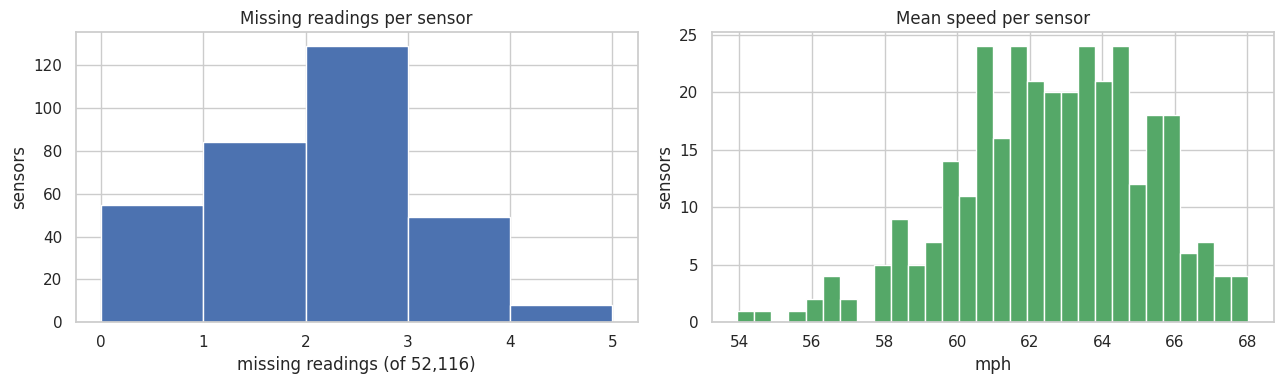

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
missing_per_sensor = per_sensor.n - per_sensor.valid
axes[0].hist(missing_per_sensor, bins=range(0, int(missing_per_sensor.max()) + 2), color="#4c72b0", edgecolor="white")
axes[0].set(title="Missing readings per sensor", xlabel="missing readings (of 52,116)", ylabel="sensors")
axes[1].hist(per_sensor.mean_speed, bins=30, color="#55a868", edgecolor="white")
axes[1].set(title="Mean speed per sensor", xlabel="mph", ylabel="sensors")
fig.tight_layout(); save(fig, "01_per_sensor_observations")

### 2.3 Daily coverage heat-map (sensor × day)
Each cell = valid readings that day / 288. Dark cells would reveal sensor outages.

saved reports/figures/eda/02_daily_coverage_heatmap.png
sensor-days below 100% coverage: 521 of 58825
worst sensor-day coverage      : 99.65%


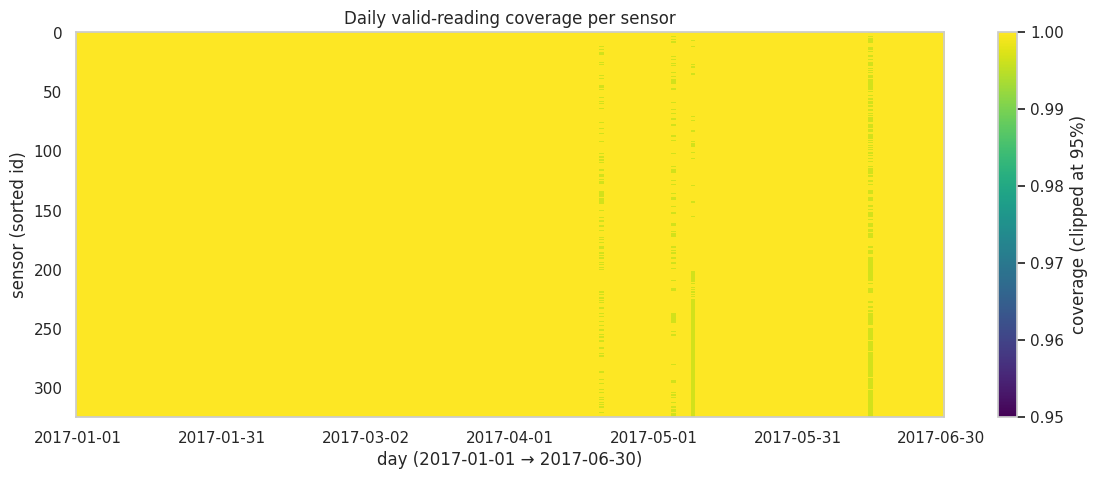

In [7]:
daily = (r.groupBy("sensor_id", "date")
           .agg(F.sum((~F.col("is_missing")).cast("int")).alias("valid"), F.count("*").alias("n"))
           .toPandas())
daily["coverage"] = daily.valid / daily.n
heat = daily.pivot(index="sensor_id", columns="date", values="coverage").sort_index()

fig, ax = plt.subplots(figsize=(14, 5))
im = ax.imshow(heat.values, aspect="auto", cmap="viridis", vmin=0.95, vmax=1.0, interpolation="nearest")
ax.set(title="Daily valid-reading coverage per sensor", xlabel="day (2017-01-01 → 2017-06-30)", ylabel="sensor (sorted id)")
ticks = np.arange(0, heat.shape[1], 30)
ax.set_xticks(ticks, [str(heat.columns[i]) for i in ticks], rotation=0)
ax.grid(False)
fig.colorbar(im, ax=ax, label="coverage (clipped at 95%)")
save(fig, "02_daily_coverage_heatmap")
print("sensor-days below 100% coverage:", int((daily.coverage < 1).sum()), "of", len(daily))
print("worst sensor-day coverage      :", f"{daily.coverage.min():.2%}")

### 2.4 Readings per day vs. expected

saved reports/figures/eda/03_readings_per_day.png


,date,timestamps,valid
70,2017-03-12,276,89700


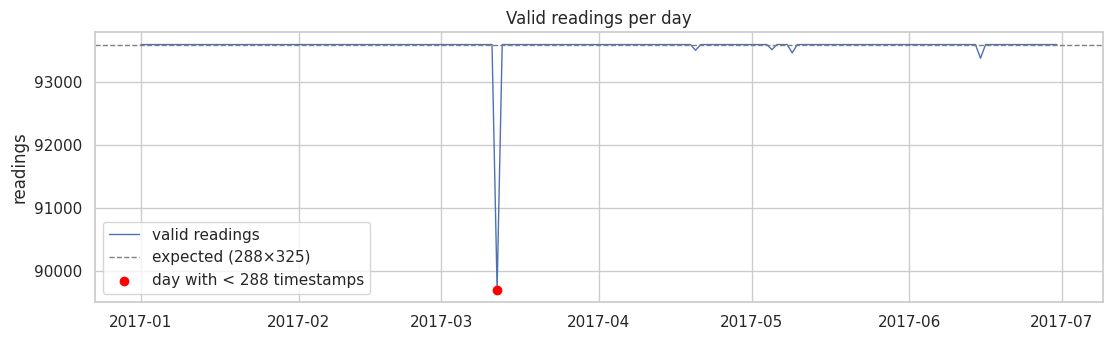

In [8]:
per_day = (r.groupBy("date")
             .agg(F.countDistinct("ts").alias("timestamps"),
                  F.sum((~F.col("is_missing")).cast("int")).alias("valid"))
             .orderBy("date").toPandas())
n_sensors = per_sensor.shape[0]
fig, ax = plt.subplots(figsize=(13, 3.5))
ax.plot(per_day.date, per_day.valid, lw=1, label="valid readings")
ax.axhline(SLOTS_PER_DAY * n_sensors, color="grey", ls="--", lw=1, label=f"expected ({SLOTS_PER_DAY}×{n_sensors})")
short = per_day[per_day.timestamps < SLOTS_PER_DAY]
ax.scatter(short.date, short.valid, color="red", zorder=3, label="day with < 288 timestamps")
ax.set(title="Valid readings per day", ylabel="readings"); ax.legend(loc="lower left")
save(fig, "03_readings_per_day")
short

### 2.5 Inter-arrival interval between consecutive readings of the same sensor (Spark window `lag`)

In [9]:
w = Window.partitionBy("sensor_id").orderBy("ts")
def interval_hist(df):
    return (df.select("sensor_id", "ts")
              .withColumn("delta_min", (F.col("ts").cast("long") - F.lag(F.col("ts").cast("long")).over(w)) / 60)
              .filter(F.col("delta_min").isNotNull())
              .groupBy("delta_min").count().orderBy(F.desc("count")).toPandas())

all_intervals = interval_hist(r)
valid_intervals = interval_hist(valid)
print("All timestamps (raw grid):"); display(all_intervals.head())
print("Valid readings only (gaps caused by missing values):"); display(valid_intervals.head(8))

All timestamps (raw grid):


,delta_min,count
0,5.0,16937050
1,65.0,325


Valid readings only (gaps caused by missing values):


,delta_min,count
0,5.0,16936008
1,10.0,521
2,65.0,325


## 3. Temporal distributions of speed

### 3.1 Overall speed distribution

saved reports/figures/eda/04_speed_distribution.png


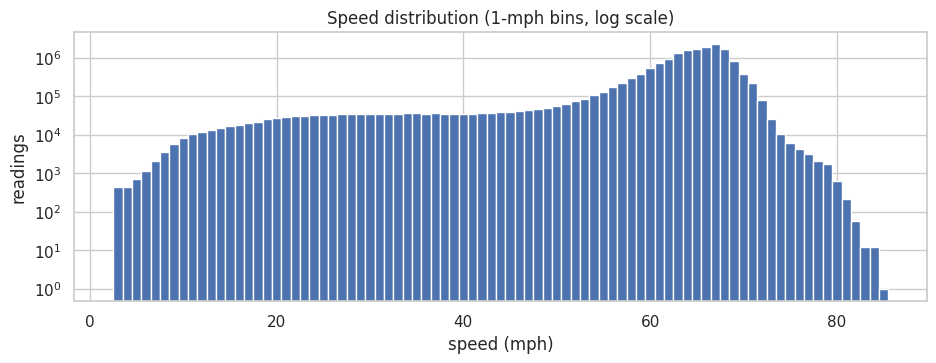

In [10]:
speed_hist = (valid.groupBy(F.floor("speed_mph").alias("mph")).count().orderBy("mph").toPandas())
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(speed_hist.mph, speed_hist["count"], width=1.0, color="#4c72b0")
ax.set_yscale("log"); ax.set(title="Speed distribution (1-mph bins, log scale)", xlabel="speed (mph)", ylabel="readings")
save(fig, "04_speed_distribution")

### 3.2 Hour-of-day profile: weekday vs. weekend

saved reports/figures/eda/05_hourly_profile.png


hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
is_weekend,,,,,,,,,,,,,,,,,,,,,,,,
weekday,66.59,66.36,66.26,66.27,66.67,66.85,62.12,56.00,53.22,55.66,60.08,62.85,63.13,62.85,60.77,56.47,53.96,50.29,53.27,61.65,65.41,66.44,66.64,66.59
weekend,66.74,66.62,66.55,66.48,66.57,66.76,66.67,66.67,66.28,65.59,64.93,64.30,63.56,63.31,63.34,63.53,63.62,63.97,64.25,65.25,65.43,66.51,66.80,66.83


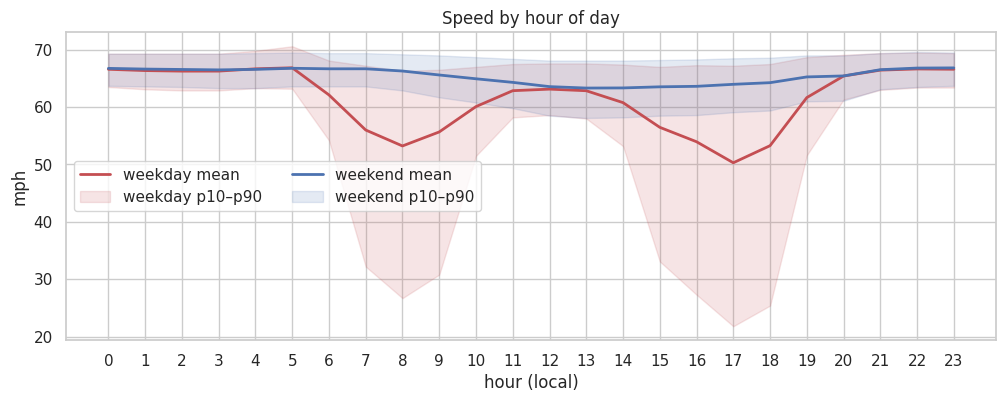

In [11]:
hourly = (valid.groupBy("is_weekend", "hour")
                .agg(F.avg("speed_mph").alias("mean"),
                     F.expr("percentile_approx(speed_mph, array(0.10, 0.50, 0.90))").alias("q"),
                     F.count("*").alias("n"))
                .orderBy("is_weekend", "hour").toPandas())
hourly[["p10", "p50", "p90"]] = pd.DataFrame(hourly.q.tolist(), index=hourly.index)

fig, ax = plt.subplots(figsize=(12, 4))
for weekend, color, label in [(False, "#c44e52", "weekday"), (True, "#4c72b0", "weekend")]:
    h = hourly[hourly.is_weekend == weekend]
    ax.plot(h.hour, h["mean"], color=color, lw=2, label=f"{label} mean")
    ax.fill_between(h.hour, h.p10, h.p90, color=color, alpha=0.15, label=f"{label} p10–p90")
ax.set(title="Speed by hour of day", xlabel="hour (local)", ylabel="mph", xticks=range(0, 24))
ax.legend(ncol=2); save(fig, "05_hourly_profile")
hourly.pivot(index="hour", columns="is_weekend", values="mean").rename(columns={False: "weekday", True: "weekend"}).round(2).T

### 3.3 Day-of-week × hour heat-map (mean speed)

saved reports/figures/eda/06_dow_hour_heatmap.png


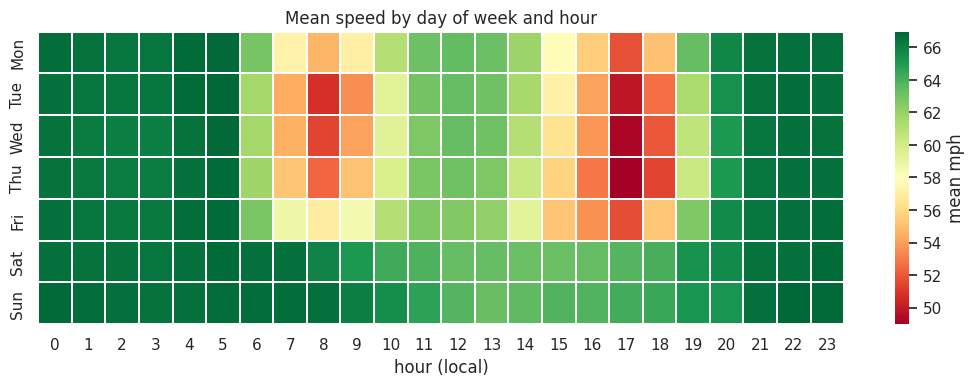

In [12]:
DOW = {1: "Sun", 2: "Mon", 3: "Tue", 4: "Wed", 5: "Thu", 6: "Fri", 7: "Sat"}
dow_hour = valid.groupBy("dow", "hour").agg(F.avg("speed_mph").alias("mean")).toPandas()
grid = dow_hour.pivot(index="dow", columns="hour", values="mean").reindex([2, 3, 4, 5, 6, 7, 1])
grid.index = [DOW[d] for d in grid.index]
fig, ax = plt.subplots(figsize=(13, 3.8))
sns.heatmap(grid, cmap="RdYlGn", ax=ax, cbar_kws={"label": "mean mph"}, linewidths=0.2)
ax.set(title="Mean speed by day of week and hour", xlabel="hour (local)", ylabel="")
ax.grid(False)
save(fig, "06_dow_hour_heatmap")

### 3.4 Monthly distribution

saved reports/figures/eda/07_monthly_boxplot.png


,month,mean,p5,p25,p50,p75,p95
0,2017-01,62.48,40.8,61.8,65.1,67.4,69.6
1,2017-02,62.65,41.7,62.0,65.1,67.4,69.7
2,2017-03,62.64,39.0,62.2,65.5,67.6,70.0
3,2017-04,63.34,45.5,62.8,65.6,67.6,69.8
4,2017-05,62.45,36.9,62.3,65.4,67.5,69.8
5,2017-06,62.18,37.8,61.6,65.0,67.3,69.5


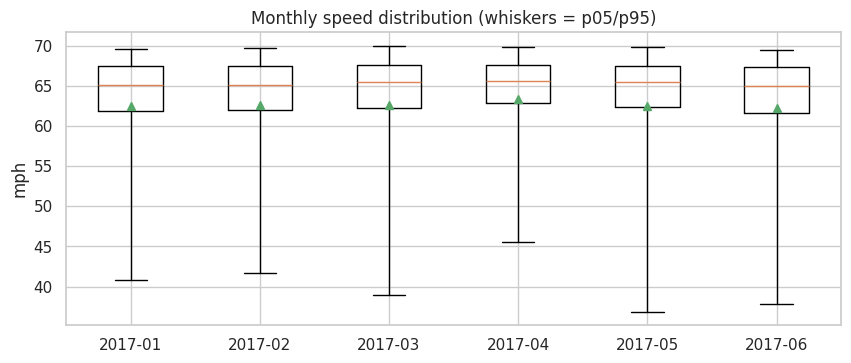

In [13]:
monthly = (valid.groupBy("month")
                .agg(F.expr("percentile_approx(speed_mph, array(0.05, 0.25, 0.5, 0.75, 0.95))").alias("q"),
                     F.avg("speed_mph").alias("mean"))
                .orderBy("month").toPandas())
stats = [dict(label=m, whislo=q[0], q1=q[1], med=q[2], q3=q[3], whishi=q[4], mean=mu, fliers=[])
         for m, q, mu in zip(monthly.month, monthly.q, monthly["mean"])]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bxp(stats, showmeans=True, showfliers=False)
ax.set(title="Monthly speed distribution (whiskers = p05/p95)", ylabel="mph")
save(fig, "07_monthly_boxplot")
monthly.assign(**{f"p{p}": monthly.q.str[i] for i, p in enumerate([5, 25, 50, 75, 95])}).drop(columns="q").round(2)

### 3.5 One week for the most congested sensor (lowest p05 speed)

saved reports/figures/eda/08_sensor_week.png


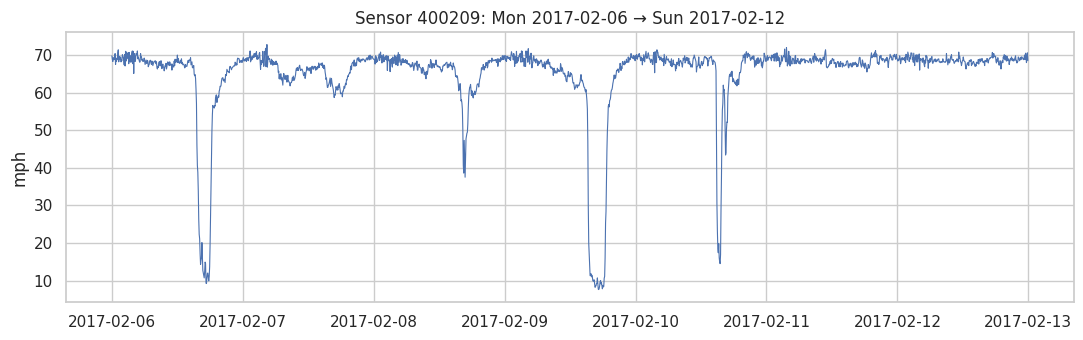

In [14]:
sid = int(per_sensor.sort_values("p05_speed").iloc[0].sensor_id)
week = (r.filter((F.col("sensor_id") == sid) & F.col("date").between("2017-02-06", "2017-02-12"))
          .select("ts", "speed_mph", "is_missing").orderBy("ts").toPandas())
fig, ax = plt.subplots(figsize=(13, 3.5))
ax.plot(week.ts, week.speed_mph, lw=0.8)
ax.scatter(week.ts[week.is_missing], [0] * int(week.is_missing.sum()), color="red", marker="x", label="missing")
ax.set(title=f"Sensor {sid}: Mon 2017-02-06 → Sun 2017-02-12", ylabel="mph")
if week.is_missing.any(): ax.legend()
save(fig, "08_sensor_week")

## 4. Spatial view

saved reports/figures/eda/09_sensor_map.png


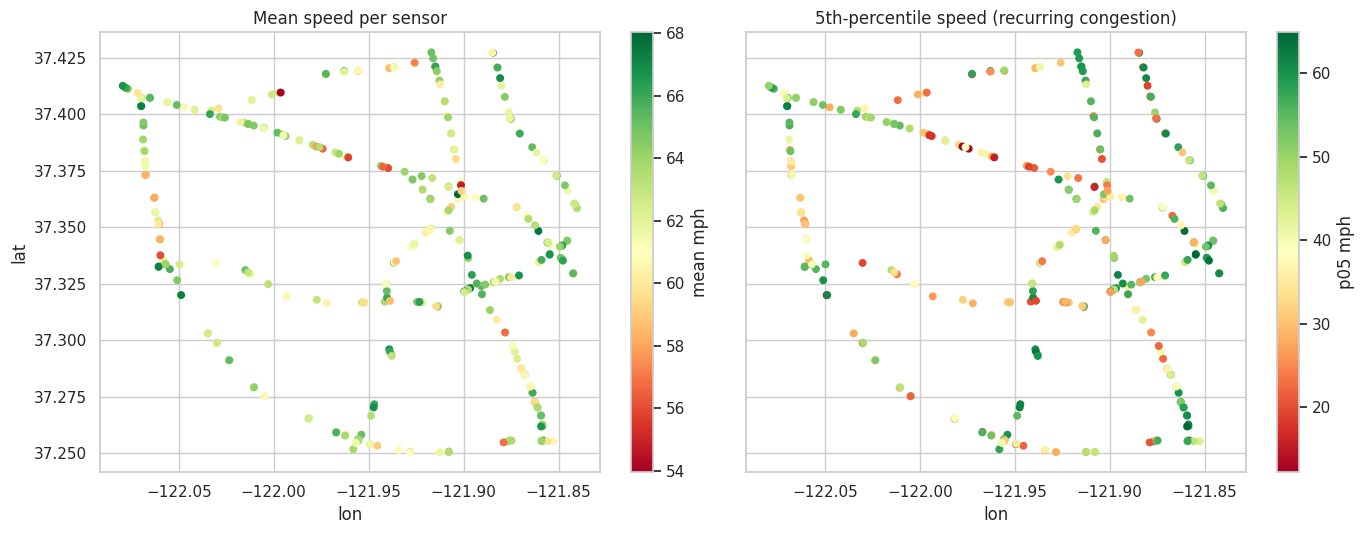

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)
sc = axes[0].scatter(per_sensor.longitude, per_sensor.latitude, c=per_sensor.mean_speed, cmap="RdYlGn", s=22)
fig.colorbar(sc, ax=axes[0], label="mean mph"); axes[0].set(title="Mean speed per sensor", xlabel="lon", ylabel="lat")
sc = axes[1].scatter(per_sensor.longitude, per_sensor.latitude, c=per_sensor.p05_speed, cmap="RdYlGn", s=22)
fig.colorbar(sc, ax=axes[1], label="p05 mph"); axes[1].set(title="5th-percentile speed (recurring congestion)", xlabel="lon")
fig.tight_layout(); save(fig, "09_sensor_map")

## 5. Provisional congestion levels

**Provisional** absolute thresholds, used only to gauge class balance. The final label definition
(e.g. relative to each sensor's free-flow speed) is decided and documented in Phase 5.

| Level | Rule |
|---|---|
| Free | speed ≥ 55 mph |
| Moderate | 40 ≤ speed < 55 mph |
| Heavy | speed < 40 mph |

,count,share
level,,
Free,"15,309,344",90.39%
Moderate,"783,981",4.63%
Heavy,"843,854",4.98%


saved reports/figures/eda/10_congestion_share_by_hour.png


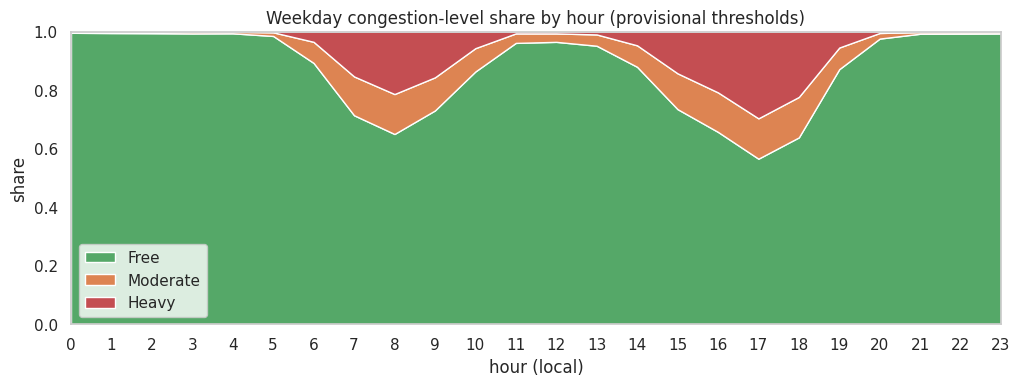

In [16]:
level = F.when(F.col("speed_mph") < 40, "Heavy").when(F.col("speed_mph") < 55, "Moderate").otherwise("Free")
cong = valid.withColumn("level", level)
share = cong.groupBy("level").count().toPandas().set_index("level")
share["share"] = share["count"] / share["count"].sum()
display(share.reindex(["Free", "Moderate", "Heavy"]).style.format({"count": "{:,}", "share": "{:.2%}"}))

by_hour = (cong.filter(~F.col("is_weekend")).groupBy("hour", "level").count().toPandas()
               .pivot(index="hour", columns="level", values="count").fillna(0)[["Free", "Moderate", "Heavy"]])
by_hour = by_hour.div(by_hour.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.stackplot(by_hour.index, by_hour.T.values, labels=by_hour.columns, colors=["#55a868", "#dd8452", "#c44e52"])
ax.set(title="Weekday congestion-level share by hour (provisional thresholds)", xlabel="hour (local)", ylabel="share",
       xlim=(0, 23), ylim=(0, 1), xticks=range(0, 24))
ax.legend(loc="lower left"); save(fig, "10_congestion_share_by_hour")

## 6. Key findings (computed)

In [17]:
wk = hourly[~hourly.is_weekend].set_index("hour")["mean"]
we = hourly[hourly.is_weekend].set_index("hour")["mean"]
heavy_peak_hour = int(by_hour["Heavy"].idxmax())
findings = {
    "readings (valid / total)": f"{int(per_sensor.valid.sum()):,} / {int(per_sensor.n.sum()):,}",
    "sensor coverage min / median": f"{per_sensor.coverage.min():.4%} / {per_sensor.coverage.median():.4%}",
    "dominant sampling interval": f"{all_intervals.iloc[0].delta_min:.0f} min ({all_intervals.iloc[0]['count'] / all_intervals['count'].sum():.4%} of steps)",
    "slowest weekday hour (mean mph)": f"{int(wk.idxmin())}:00 ({wk.min():.1f})",
    "weekday vs weekend mean mph": f"{wk.mean():.1f} vs {we.mean():.1f}",
    "Heavy share overall (provisional)": f"{share.loc['Heavy', 'share']:.2%}" if "Heavy" in share.index else "0%",
    "weekday hour with most Heavy readings": f"{heavy_peak_hour}:00 ({by_hour['Heavy'].max():.2%})",
    "most congested sensor (lowest p05)": f"{sid} (p05 {per_sensor.p05_speed.min():.1f} mph)",
}
pd.Series(findings, name="value").to_frame()

,value
readings (valid / total),"16,937,179 / 16,937,700"
sensor coverage min / median,99.9923% / 99.9962%
dominant sampling interval,5 min (99.9981% of steps)
slowest weekday hour (mean mph),17:00 (50.3)
weekday vs weekend mean mph,61.5 vs 65.4
Heavy share overall (provisional),4.98%
weekday hour with most Heavy readings,17:00 (29.63%)
most congested sensor (lowest p05),400209 (p05 12.2 mph)


**Implications for later phases**

* Observation frequency is essentially perfect (5-min grid, ~0.003 % missing): imputation can be simple
  (forward-fill / per-sensor interpolation), but the ~0.7 % flat-line runs flagged in validation (C10) should be
  treated as suspect in feature engineering.
* Strong, repeatable weekday AM/PM peaks and a weaker weekend profile → `hour`, `day_of_week`, `is_weekend`
  plus lagged speeds will be core features (Phase 5).
* Heavy congestion is a small minority class → use **class weights** and **macro-F1** in Phase 6 (a gap noted
  in the reference deck), and a **chronological** train/test split.

In [18]:
r.unpersist()
spark.stop()